# 08 — Final training, test, calibration and explanation

1. **Pick** the model with the best validation PR-AUC (from `06` and `07`).
2. **Train** it on the training cohorts with its best settings.
3. **Calibrate** it on the validation cohorts, so that "70%" really means about 70 in 100 such businesses.
4. **Test** it **once** on the test cohort, which no notebook has used before.
5. **Explain** it with SHAP: which inputs move the score, and how much.
6. **Save** the model and its report for the FastAPI `/predict` service.

**Reads:** `pipeline/05_*`, `06_baseline_results.csv`, `07_best_params.json`, `07_tuning_results.csv`.
**Saves:** `pipeline/models/survival_model.joblib` and `pipeline/models/model_report.json`.

**The notebooks, in order** (each one loads what the one before saved, so nothing is downloaded or read from Excel twice):

| # | Notebook | Saves (in `Darb DataSets/pipeline`) |
|---|---|---|
| 00 | `00_download` | `00_raw/`: an exact copy of every raw file, as fast parquet |
| 01 | `01_eda_raw` | `01_quarter_quality.csv`: how complete each MC quarter is |
| 02 | `02_preprocess_businesses` | `02_businesses.parquet`: one row per business, with its label |
| 03 | `03_preprocess_economic` | `03_*.parquet`: GDP, SME, SAMA and licensing features |
| 04 | `04_eda_clean` | nothing (looks only) |
| 05 | `05_features` | `05_model_table.parquet`: the model's inputs and the time split |
| 06 | `06_baseline` | `06_baseline_results.csv` |
| 07 | `07_tuning` | `07_best_params.json`, `07_tuning_results.csv` |
| 08 | `08_final_training` | `models/`: the final model and its report |

**Rules:** raw files are never changed · nothing is dropped (problems get a flag) · data never goes into Git ·
clear all outputs before committing.

### Setup
Finds the data folder. **Locally** it is `~/darb-data` (or the folder in the `DARB_DATA` setting), a copy of the
team's Drive folder **Darb DataSets**. **On Colab** it is Darb DataSets itself: add a shortcut to it in your My
Drive first, and upload the files of `ml/src` to `/content`.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/Darb DataSets')   # a shortcut to the team folder in your My Drive
    SRC_DIR = Path('/content')                                # upload the files of ml/src here
    !pip install -q python-calamine lightgbm xgboost shap
else:
    DATA_DIR = Path(os.environ.get('DARB_DATA', Path.home() / 'darb-data'))   # local copy of Darb DataSets
    SRC_DIR = Path.cwd().parent / 'src'

PIPE = DATA_DIR / 'pipeline'          # every notebook saves its results here (never in Git)
PIPE.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))


def need(path, notebook):
    """Stops with a clear message when a file from an earlier notebook is missing."""
    if not Path(path).exists():
        raise FileNotFoundError(f'{Path(path).name} not found: run {notebook} first.')
    return Path(path)


print('Colab' if IN_COLAB else 'Local', '| data:', DATA_DIR, '| results:', PIPE)

Local | data: /Users/halaalsabbar/darb-data | results: /Users/halaalsabbar/darb-data/pipeline


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from model_tools import fis, fis_band, make_model, make_preprocessor, scores

table = pd.read_parquet(need(PIPE / '05_model_table.parquet', '05_features'))
spec = json.loads((PIPE / '05_features.json').read_text())
CATEGORICAL, NUMERIC, TARGET = spec['categorical'], spec['numeric'], spec['target']
INPUTS = CATEGORICAL + NUMERIC
for column in CATEGORICAL:
    table[column] = table[column].astype(object).where(table[column].notna(), np.nan)
parts = {name: table[table['split'] == name] for name in ['train', 'validation', 'test']}
X = {name: part[INPUTS] for name, part in parts.items()}
y = {name: part[TARGET].to_numpy() for name, part in parts.items()}
pd.set_option('display.width', 200)
print({name: f'{len(part):,} rows, {y[name].mean():.1%} failed' for name, part in parts.items()})

{'train': '89,800 rows, 17.2% failed', 'validation': '93,949 rows, 8.5% failed', 'test': '76,547 rows, 12.3% failed'}


## 1 — Pick the model

In [3]:
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

results = pd.read_csv(need(PIPE / '07_tuning_results.csv', '07_tuning'), index_col='model')
best_params = json.loads((PIPE / '07_best_params.json').read_text())
candidates = results.drop(index='always the average')
winner = candidates['PR-AUC'].idxmax()
print(results.round(4).to_string())
print('\nChosen (best validation PR-AUC):', winner)

def build_model(name):
    if name == 'logistic regression':
        return make_model(make_preprocessor(NUMERIC, CATEGORICAL, scale_numbers=True),
                          LogisticRegression(class_weight='balanced', max_iter=3000))
    if name.startswith('LightGBM'):
        return make_model(make_preprocessor(NUMERIC, CATEGORICAL, scale_numbers=False),
                          LGBMClassifier(subsample_freq=1, verbose=-1, random_state=42, **best_params['LightGBM']))
    return make_model(make_preprocessor(NUMERIC, CATEGORICAL, scale_numbers=False),
                      XGBClassifier(tree_method='hist', eval_metric='aucpr', random_state=42, **best_params['XGBoost']))

                     PR-AUC  ROC-AUC  recall (failed)  precision (failed)   Brier  failure rate
model                                                                                          
always the average   0.0850   0.5000           0.0000              0.0000  0.0853         0.085
logistic regression  0.1886   0.7696           0.7065              0.1719  0.1430         0.085
LightGBM (tuned)     0.1841   0.7588           0.8576              0.1629  0.1552         0.085
XGBoost (tuned)      0.1854   0.7585           0.0039              0.4079  0.0736         0.085

Chosen (best validation PR-AUC): logistic regression


## 2 — Train, then calibrate on the validation cohorts
Models trained with extra weight on failed businesses (or boosted trees in general) give chances that are too high
or too low. **Isotonic calibration** learns, on the validation cohorts, how to turn the model's raw score into a
true chance. The model itself is frozen while this is learned.

In [4]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator

model = build_model(winner).fit(X['train'], y['train'])
calibrated = CalibratedClassifierCV(FrozenEstimator(model), method='isotonic').fit(X['validation'], y['validation'])

raw_val = model.predict_proba(X['validation'])[:, 1]
cal_val = calibrated.predict_proba(X['validation'])[:, 1]
print(pd.DataFrame({'before calibration': scores(y['validation'], raw_val),
                    'after calibration': scores(y['validation'], cal_val)}).T.round(4).to_string())

                    PR-AUC  ROC-AUC  recall (failed)  precision (failed)   Brier  failure rate
before calibration  0.1886   0.7696           0.7065              0.1719  0.1430         0.085
after calibration   0.1855   0.7709           0.0014              0.7857  0.0714         0.085


### The threshold for "high risk"
After calibration the chances are honest, so a business flagged at 0.5 must be more likely to fail than not:
few are. The threshold used for recall and precision is chosen on the **validation** cohorts as the one with the
best balance of the two (F1). It is saved with the model.

In [5]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y['validation'], cal_val)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-9)
THRESHOLD = float(thresholds[np.argmax(f1[:-1])])
print(f'Threshold: {THRESHOLD:.3f} | validation recall {recall[np.argmax(f1[:-1])]:.1%}, precision {precision[np.argmax(f1[:-1])]:.1%}')

Threshold: 0.141 | validation recall 82.7%, precision 16.7%


## 3 — The test (used once)
Everything above was decided without the test cohort. Its scores are the honest estimate of how the model does
on new businesses.

In [6]:
p_test = calibrated.predict_proba(X['test'])[:, 1]
test_scores = scores(y['test'], p_test, threshold=THRESHOLD)
validation_scores = scores(y['validation'], cal_val, threshold=THRESHOLD)
pd.DataFrame({'validation': validation_scores, 'test': test_scores}).T.round(4)

,PR-AUC,ROC-AUC,recall (failed),precision (failed),Brier,failure rate
validation,0.1855,0.7709,0.8268,0.1672,0.0714,0.0850
test,0.1519,0.5942,0.8373,0.1494,0.1073,0.1233


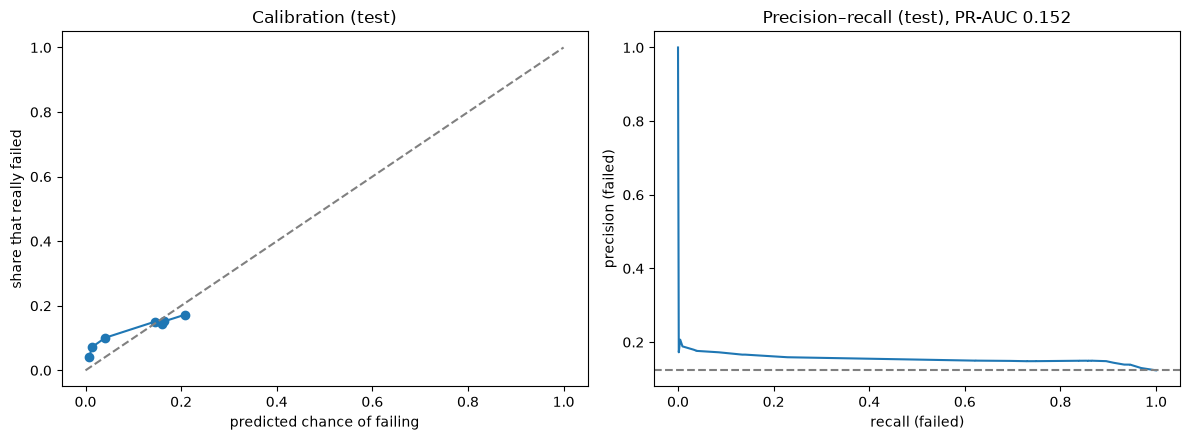

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
observed, predicted = calibration_curve(y['test'], p_test, n_bins=10, strategy='quantile')
axes[0].plot(predicted, observed, marker='o'); axes[0].plot([0, 1], [0, 1], color='grey', ls='--')
axes[0].set(xlabel='predicted chance of failing', ylabel='share that really failed', title='Calibration (test)')
precision, recall, _ = precision_recall_curve(y['test'], p_test)
axes[1].plot(recall, precision); axes[1].axhline(y['test'].mean(), color='grey', ls='--')
axes[1].set(xlabel='recall (failed)', ylabel='precision (failed)', title=f'Precision–recall (test), PR-AUC {test_scores["PR-AUC"]:.3f}')
plt.tight_layout(); plt.show()

## 4 — The Founder Intelligence Score on the test cohort
FIS = 100 × chance of still being registered after one year. For each band: how many test businesses fall in it,
and how many of them really survived. A good score has clearly different survival rates per band.

In [8]:
score = fis(p_test)
bands = pd.DataFrame({'band': fis_band(score), 'survived': 1 - y['test']})
bands.groupby('band', observed=False).agg(businesses=('survived', 'size'), really_survived=('survived', 'mean')).style.format({'really_survived': '{:.1%}'})

,businesses,really_survived
band,,
0–39 lower,0,nan%
40–69 moderate,87,82.8%
70–100 higher,76460,87.7%


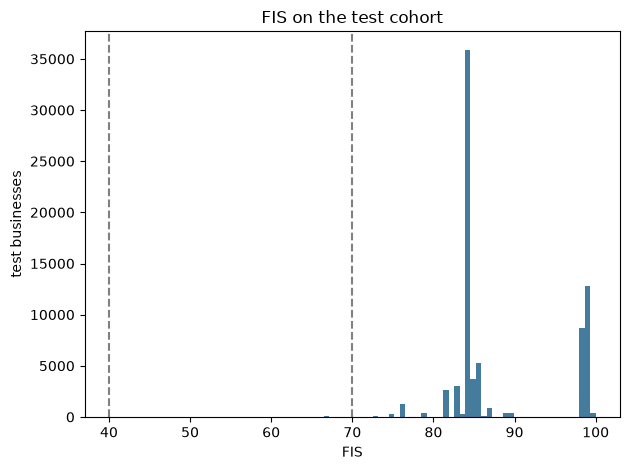

In [9]:
plt.hist(score, bins=50, color='#457b9d'); plt.axvline(40, color='grey', ls='--'); plt.axvline(70, color='grey', ls='--')
plt.xlabel('FIS'); plt.ylabel('test businesses'); plt.title('FIS on the test cohort'); plt.tight_layout(); plt.show()

## 5 — Explanation with SHAP
SHAP splits each business's predicted risk into a part per input. The chart shows, over 3,000 test businesses,
which inputs move the risk the most (on average, either way). The FastAPI service uses the same method to tell a
founder which of their answers raised or lowered their score.

/Users/halaalsabbar/darb-data/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Background dataset has 3000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=3000 when initializing the masker.


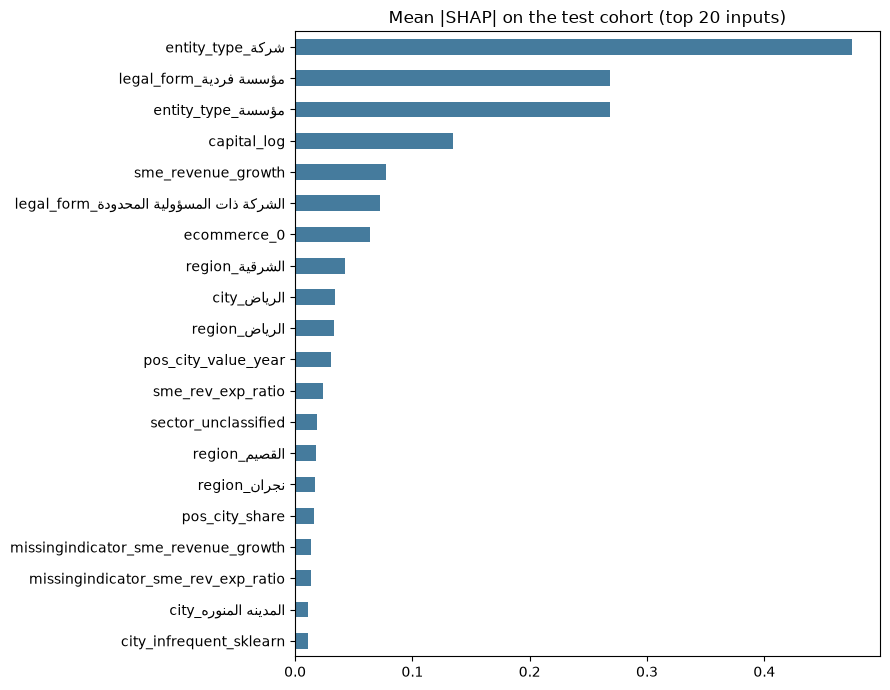

In [10]:
import shap

sample = X['test'].sample(min(3000, len(X['test'])), random_state=42)
prepared = model.named_steps['prepare'].transform(sample)
names = model.named_steps['prepare'].get_feature_names_out()
estimator = model.named_steps['model']
explainer = shap.TreeExplainer(estimator) if not isinstance(estimator, LogisticRegression) else shap.LinearExplainer(estimator, prepared)
values = explainer.shap_values(prepared)
values = values[1] if isinstance(values, list) else values
importance = pd.Series(np.abs(values).mean(axis=0), index=names).sort_values(ascending=False)
importance.head(20).sort_values().plot.barh(figsize=(9, 7), color='#457b9d', title='Mean |SHAP| on the test cohort (top 20 inputs)')
plt.tight_layout(); plt.show()

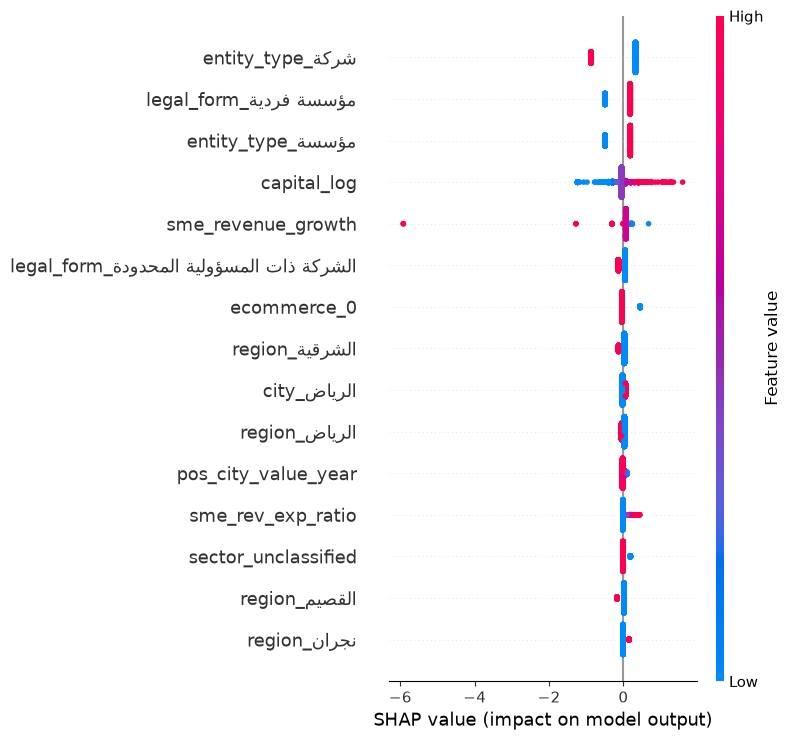

In [11]:
shap.summary_plot(values, pd.DataFrame(prepared, columns=names), max_display=15, show=False)
plt.tight_layout(); plt.show()

## 6 — Save the model and its report
The saved model takes the raw inputs (the columns in `05_features.json`) and returns the calibrated chance of
failing; FIS = 100 × (1 − that chance).

In [12]:
import datetime
import joblib
import sklearn

MODEL_DIR = PIPE / 'models'
MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(calibrated, MODEL_DIR / 'survival_model.joblib')
report = {
    'made_on': datetime.date.today().isoformat(), 'model': winner, 'params': best_params.get(winner.split(' ')[0], {}),
    'inputs': {'categorical': CATEGORICAL, 'numeric': NUMERIC}, 'split': spec['split'], 'cohort_qualities': spec['cohort_qualities'],
    'threshold': THRESHOLD, 'calibration': 'isotonic, on the validation cohorts',
    'validation': {k: round(float(v), 4) for k, v in validation_scores.items()},
    'test': {k: round(float(v), 4) for k, v in test_scores.items()},
    'top_inputs_shap': importance.head(15).round(5).to_dict(),
    'versions': {'scikit-learn': sklearn.__version__, 'shap': shap.__version__},
}
(MODEL_DIR / 'model_report.json').write_text(json.dumps(report, indent=2, ensure_ascii=False))
print('Saved', MODEL_DIR / 'survival_model.joblib', 'and', MODEL_DIR / 'model_report.json')

Saved /Users/halaalsabbar/darb-data/pipeline/models/survival_model.joblib and /Users/halaalsabbar/darb-data/pipeline/models/model_report.json
